In [1]:
!pip install timm -q

from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

import os
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
import timm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Evaluation Device:", device)

Evaluation Device: cuda


In [2]:
test_dir = "/kaggle/input/datasets/abdelghaniaaba/wildfire-prediction-dataset/test"

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

test_dataset = datasets.ImageFolder(test_dir, transform=test_transform)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

print("Test samples count:", len(test_dataset))
print("Class categories:", test_dataset.classes)

Test samples count: 6300
Class categories: ['nowildfire', 'wildfire']


In [3]:
model_resnet = models.resnet18(weights=None)
model_resnet.fc = nn.Linear(model_resnet.fc.in_features, 2)
model_resnet.load_state_dict(torch.load("/kaggle/input/models/rahulnagilla/resnet18/pytorch/default/1/ResNet18 Wildfire.pth", map_location=device))
model_resnet = model_resnet.to(device).eval()

model_mobilenet = models.mobilenet_v2(weights=None)
model_mobilenet.classifier[1] = nn.Linear(model_mobilenet.last_channel, 2)
model_mobilenet.load_state_dict(torch.load("/kaggle/input/models/rahulnagilla/mobilenetv2/transformers/default/1/MobileNetV2 Wildfire.pth", map_location=device))
model_mobilenet = model_mobilenet.to(device).eval()

model_vit = timm.create_model('vit_tiny_patch16_224', pretrained=False, num_classes=2)
model_vit.load_state_dict(torch.load("/kaggle/input/models/rahulnagilla/itny-vit/pytorch/default/1/Vit Tiny Wildfire.pth", map_location=device))
model_vit = model_vit.to(device).eval()

model_deit = timm.create_model('deit_tiny_patch16_224', pretrained=False, num_classes=2)
model_deit.load_state_dict(torch.load("/kaggle/input/models/rahulnagilla/tiny-diet/pytorch/default/1/Deit Tiny Wildfire.pth", map_location=device))
model_deit = model_deit.to(device).eval()

print("All four model checkpoints loaded successfully!")

All four model checkpoints loaded successfully!


In [4]:
models_dict = {
    "ResNet-18": model_resnet,
    "MobileNetV2": model_mobilenet,
    "ViT-Tiny": model_vit,
    "DeiT-Tiny": model_deit
}

results_detailed = {}

for name, model in models_dict.items():
    preds_list = []
    labels_list = []
    
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            preds_list.extend(preds.cpu().numpy())
            labels_list.extend(labels.numpy())
            
    # output_dict=True gives us a dictionary of class-wise precision, recall, and f1-score
    report = classification_report(labels_list, preds_list, output_dict=True)
    results_detailed[name] = report
    print(f"Evaluated: {name}")

Evaluated: ResNet-18
Evaluated: MobileNetV2
Evaluated: ViT-Tiny
Evaluated: DeiT-Tiny


In [6]:

rows = []
for name, rep in results_detailed.items():
    for cls_idx, cls_name in enumerate(test_dataset.classes):
        cls_str = str(cls_idx)
        rows.append({
            "Model": name,
            "Class": cls_name,
            "Precision": f"{rep[cls_str]['precision']:.4f}",
            "Recall": f"{rep[cls_str]['recall']:.4f}",
            "F1-Score": f"{rep[cls_str]['f1-score']:.4f}",
            "Support": int(rep[cls_str]['support'])
        })

df_classwise = pd.DataFrame(rows)
print("\n--- Granular Class-Wise Performance Breakdown ---")
print(df_classwise.to_string(index=False))


--- Granular Class-Wise Performance Breakdown ---
      Model      Class Precision Recall F1-Score  Support
  ResNet-18 nowildfire    0.9866 0.9922   0.9894     2820
  ResNet-18   wildfire    0.9936 0.9891   0.9914     3480
MobileNetV2 nowildfire    0.9898 0.9968   0.9933     2820
MobileNetV2   wildfire    0.9974 0.9917   0.9945     3480
   ViT-Tiny nowildfire    0.9887 0.9940   0.9913     2820
   ViT-Tiny   wildfire    0.9951 0.9908   0.9929     3480
  DeiT-Tiny nowildfire    0.9933 0.9929   0.9931     2820
  DeiT-Tiny   wildfire    0.9943 0.9945   0.9944     3480


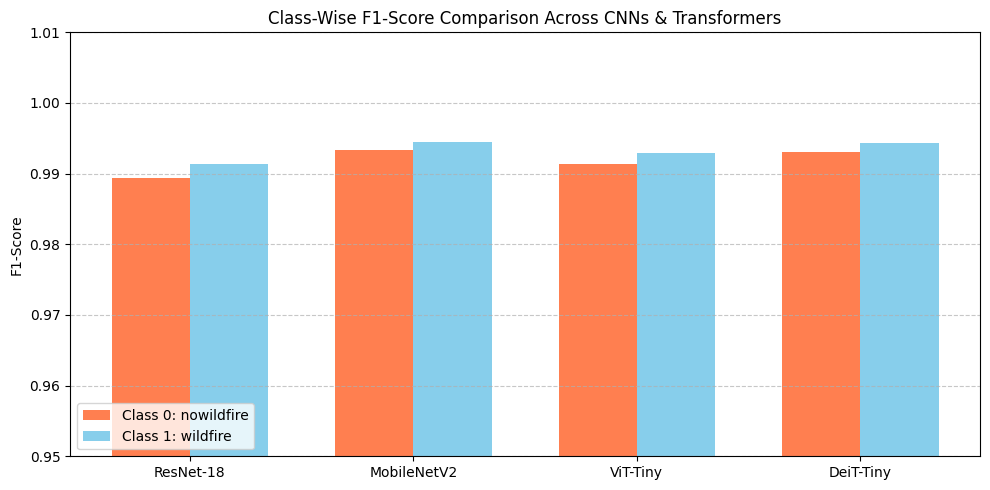

In [7]:
models_list = list(models_dict.keys())
classes = test_dataset.classes

x = np.arange(len(models_list))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

# Extract class 0 and class 1 F1-scores for each model
f1_class_0 = [results_detailed[m]['0']['f1-score'] for m in models_list]
f1_class_1 = [results_detailed[m]['1']['f1-score'] for m in models_list]

rects1 = ax.bar(x - width/2, f1_class_0, width, label=f'Class 0: {classes[0]}', color='coral')
rects2 = ax.bar(x + width/2, f1_class_1, width, label=f'Class 1: {classes[1]}', color='skyblue')

ax.set_ylabel('F1-Score')
ax.set_title('Class-Wise F1-Score Comparison Across CNNs & Transformers')
ax.set_xticks(x)
ax.set_xticklabels(models_list)
ax.set_ylim(0.95, 1.01)  # Zoomed in near the 95-100% ceiling to highlight fine differences
ax.legend(loc='lower left')
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [8]:
!pip install grad-cam timm -q

from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

import os
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
import timm
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("XAI Device:", device)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
XAI Device: cuda


In [9]:
test_dir = "/kaggle/input/datasets/abdelghaniaaba/wildfire-prediction-dataset/test"
sample_class = os.listdir(test_dir)[0]
sample_img_name = os.listdir(os.path.join(test_dir, sample_class))[0]
img_path = os.path.join(test_dir, sample_class, sample_img_name)

raw_image = Image.open(img_path).convert('RGB').resize((224, 224))
rgb_img = np.array(raw_image) / 255.0

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
input_tensor = transform(raw_image).unsqueeze(0).to(device)

model_resnet = models.resnet18(weights=None)
model_resnet.fc = nn.Linear(model_resnet.fc.in_features, 2)
model_resnet.load_state_dict(torch.load("/kaggle/input/models/rahulnagilla/resnet18/pytorch/default/1/ResNet18 Wildfire.pth", map_location=device))
model_resnet = model_resnet.to(device).eval()

model_vit = timm.create_model('vit_tiny_patch16_224', pretrained=False, num_classes=2)
model_vit.load_state_dict(torch.load("/kaggle/input/models/rahulnagilla/itny-vit/pytorch/default/1/Vit Tiny Wildfire.pth", map_location=device))
model_vit = model_vit.to(device).eval()

print("Loaded test image and models successfully!")

Loaded test image and models successfully!


In [10]:
target_layers = [model_resnet.layer4[-1]]
cam = GradCAM(model=model_resnet, target_layers=target_layers)

grayscale_cam = cam(input_tensor=input_tensor, targets=None)
grayscale_cam = grayscale_cam[0, :]

visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

print("Grad-CAM generated for ResNet-18.")

Grad-CAM generated for ResNet-18.


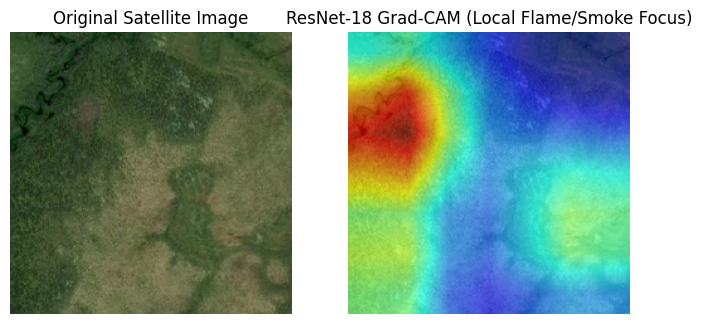

In [11]:
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(rgb_img)
plt.title("Original Satellite Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(visualization)
plt.title("ResNet-18 Grad-CAM (Local Flame/Smoke Focus)")
plt.axis('off')

plt.show()

Predicted class: 1
Number of image patches: 196
ViT Attention Rollout generated successfully!


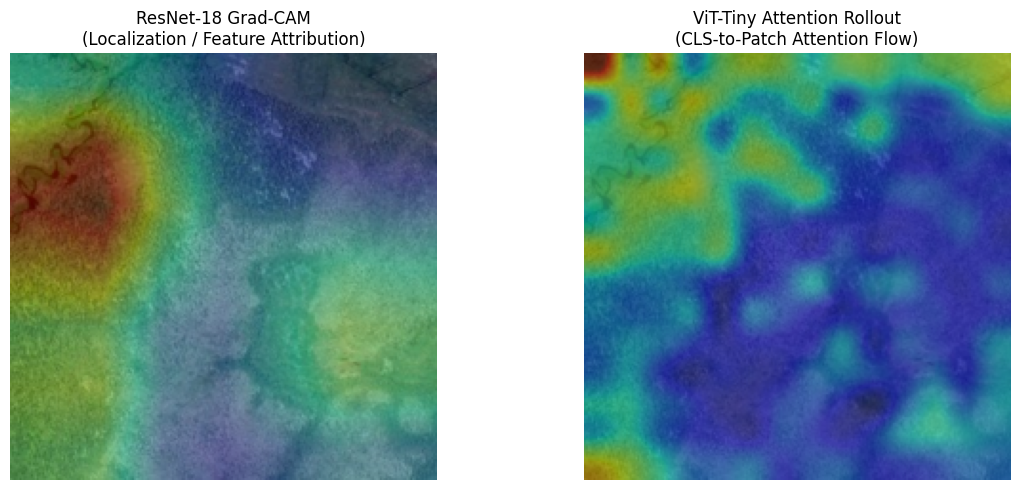

In [13]:
# 6. Foolproof ViT Global Attribution via Input Gradients
import numpy as np
from PIL import Image
import torch
import matplotlib.pyplot as plt

# ============================================================
# 1. Capture attention weights from every ViT layer
# ============================================================

model_vit.eval()
input_tensor_vit = input_tensor.clone().detach()

attention_maps = []
hooks = []
original_fused_flags = []

blocks = getattr(model_vit, "blocks", None)

if blocks is None:
    raise RuntimeError(
        "Could not find model_vit.blocks. "
        "This code expects a timm Vision Transformer."
    )

attn_modules = []

for block in blocks:
    attn = getattr(block, "attn", None)

    if attn is None or not hasattr(attn, "attn_drop"):
        raise RuntimeError(
            "Could not find attn_drop in a Transformer block. "
            "The model may use a different attention implementation."
        )

    attn_modules.append(attn)


def save_attention(module, inputs, output):
    # Expected shape: [batch, heads, tokens, tokens]
    attention_maps.append(output.detach().float().cpu())


# Disable fused attention temporarily so timm exposes
# the attention matrix through attn_drop.
for attn in attn_modules:
    if hasattr(attn, "fused_attn"):
        original_fused_flags.append((attn, attn.fused_attn))
        attn.fused_attn = False

    hooks.append(
        attn.attn_drop.register_forward_hook(save_attention)
    )

try:
    with torch.no_grad():
        output = model_vit(input_tensor_vit)
finally:
    # Always remove hooks and restore the original model settings.
    for hook in hooks:
        hook.remove()

    for attn, original_flag in original_fused_flags:
        attn.fused_attn = original_flag


if len(attention_maps) != len(attn_modules):
    raise RuntimeError(
        f"Captured {len(attention_maps)} attention maps for "
        f"{len(attn_modules)} Transformer blocks. "
        "Check your model's attention implementation."
    )

pred_class = output.argmax(dim=1).item()


# ============================================================
# 2. Attention rollout across all layers
# ============================================================

num_tokens = attention_maps[0].shape[-1]

# Start with an identity matrix.
joint_attention = torch.eye(num_tokens, dtype=torch.float32)

for layer_attention in attention_maps:

    # Average attention across heads.
    attention = layer_attention[0].mean(dim=0)

    # Add residual connection.
    identity = torch.eye(
        attention.shape[-1],
        dtype=attention.dtype
    )
    attention = attention + identity

    # Normalize each row.
    attention = attention / attention.sum(
        dim=-1, keepdim=True
    ).clamp(min=1e-8)

    # Accumulate attention flow through the layers.
    joint_attention = attention @ joint_attention


# The CLS token is normally at index 0.
# Extract its rollout scores for image patches.
num_prefix_tokens = int(
    getattr(model_vit, "num_prefix_tokens", 1)
)

patch_relevance = joint_attention[
    0, num_prefix_tokens:
]

print("Predicted class:", pred_class)
print("Number of image patches:", patch_relevance.numel())


# ============================================================
# 3. Convert patch scores into a spatial heatmap
# ============================================================

patch_embed = getattr(model_vit, "patch_embed", None)
patch_size = getattr(patch_embed, "patch_size", None)

in_h, in_w = input_tensor_vit.shape[-2:]

grid_h = grid_w = None

if patch_size is not None:
    if isinstance(patch_size, int):
        ph, pw = patch_size, patch_size
    else:
        ph, pw = patch_size

    grid_h, grid_w = in_h // ph, in_w // pw


num_patches = patch_relevance.numel()

# Check that the grid matches the number of patch tokens.
if grid_h is None or grid_h * grid_w != num_patches:
    model_grid = getattr(patch_embed, "grid_size", None)

    if (
        model_grid is not None
        and int(model_grid[0]) * int(model_grid[1]) == num_patches
    ):
        grid_h, grid_w = int(model_grid[0]), int(model_grid[1])
    else:
        # Fallback for square ViT inputs.
        side = int(np.sqrt(num_patches))

        if side * side != num_patches:
            raise RuntimeError(
                "Could not infer patch-grid dimensions. "
                "Check the model's patch embedding and prefix tokens."
            )

        grid_h, grid_w = side, side


vit_cam = patch_relevance.reshape(
    grid_h, grid_w
).numpy()

# Normalize scores to [0, 1].
vit_cam = (
    (vit_cam - vit_cam.min())
    / (vit_cam.max() - vit_cam.min() + 1e-8)
)


# ============================================================
# 4. Upsample the patch map to the original image size
# ============================================================

heatmap = Image.fromarray(
    np.uint8(np.clip(vit_cam, 0, 1) * 255)
)

if isinstance(rgb_img, Image.Image):
    out_w, out_h = rgb_img.size
else:
    out_h, out_w = np.asarray(rgb_img).shape[:2]

vit_cam_resized = np.asarray(
    heatmap.resize(
        (out_w, out_h),
        Image.Resampling.BICUBIC
    ),
    dtype=np.float32
) / 255.0

print("ViT Attention Rollout generated successfully!")


# ============================================================
# 5. Side-by-side visual comparison
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(rgb_img)
axes[0].imshow(visualization, cmap="jet", alpha=0.5)
axes[0].set_title("ResNet-18 Grad-CAM\n(Localization / Feature Attribution)")
axes[0].axis("off")

axes[1].imshow(rgb_img)
axes[1].imshow(vit_cam_resized, cmap="jet", alpha=0.5)
axes[1].set_title(
    "ViT-Tiny Attention Rollout\n(CLS-to-Patch Attention Flow)"
)
axes[1].axis("off")

plt.tight_layout()
plt.show()